# Curvas de aprendizado — treino por épocas × one-shot, todas as sementes

A semente muda a divisão treino/validação/teste, o mapeamento das RAMs e o embaralhamento das épocas; aqui **todas as sementes disponíveis aparecem juntas**, sobrepostas no mesmo painel. A **cor** identifica a semente e o **estilo** da linha identifica a série:

- **linha cheia com marcadores**: acurácia de validação (com bleaching) a cada época da configuração de épocas **escolhida pela validação** daquela semente — a mesma das tabelas do `summarize.py`. A época 0 é a primeira passada (classifica antes de gravar, penaliza e reforça); a curva segue até o early stopping parar;
- **ponto maior**: a melhor época, que é o modelo entregue;
- **tracejada**: validação do **one-shot escolhido** (o benchmark);
- **pontilhada**: validação do **one-shot com os mesmos bits e n-tupla** da configuração de épocas — isola o efeito do treino por épocas.

Abaixo do nome de cada painel há uma linha por semente: `sK · n` n-tupla `· b · ρ₀ · τ` da configuração de épocas, e `teste A × B` = teste do treino por épocas × teste do one-shot escolhido.

Os resultados vêm de `experiments/results/<conjunto>/<binarização>/seed<k>.jsonl` (gerados pelo `run_grid.py`). Uma semente entra quando tem os dois modelos; mnist, fashion-mnist e jsc têm só a semente 1. O teste não participa de nenhuma escolha.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

# the notebook lives in experiments/, but also works when started from the repository root
HERE = Path.cwd() if (Path.cwd() / "summarize.py").exists() else Path.cwd() / "experiments"
sys.path.insert(0, str(HERE))
import summarize as sm

RESULTS_DIR = HERE / "results"
FIGURES_DIR = HERE / "figures"
SEEDS = None  # None: every seed with results for both models; or a list, e.g. [0, 1]
SAVE_FIGURES = True  # PNG and HTML in experiments/figures/
ENCODINGS = {"distributive": "Termômetro distributivo", "thermometer": "Termômetro comum"}

# one categorical slot per seed, fixed by the seed number (reference palette, light surface)
SEED_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]


def seed_color(seed):
    return SEED_COLORS[seed % len(SEED_COLORS)]

## Configuração escolhida e referências de cada semente

In [2]:
def epoch_key(r):
    return (r["bits"], r["address"], r["b"], r["rho0"], r["tau"])


def panel_record(dataset, encoding, seed, rows):
    """chosen epoch configuration of one seed (same choice as summarize.py) and its one-shot references"""
    chosen = sm.choose(rows)
    if len(chosen) < len(sm.MODELS):  # incomplete grid
        return None
    cfg, ep_test, ep_val = chosen["epochs + bleaching"]
    row = next(r for r in rows if r["kind"] == "epochs"
               and epoch_key(r) == (cfg["bits"], cfg["address"], cfg["b"], cfg["rho0"], cfg["tau"]))
    os_cfg, os_test, os_val = chosen["one-shot + bleaching"]
    same = next(r for r in rows if r["kind"] == "oneshot"
                and r["bits"] == cfg["bits"] and r["address"] == cfg["address"])
    return dict(
        dataset=dataset, encoding=encoding, seed=seed,
        bits=cfg["bits"], address=cfg["address"], b=cfg["b"], rho0=cfg["rho0"], tau=cfg["tau"],
        best_epoch=row["bestEpoch"], epochs_run=len(row["accValPerEpoch"]), val_curve=row["accValPerEpoch"],
        epochs_val=ep_val["acc"], epochs_test=ep_test["acc"],
        oneshot_bits=os_cfg["bits"], oneshot_address=os_cfg["address"],
        oneshot_val=os_val["acc"], oneshot_test=os_test["acc"],
        same_val=same["bleaching"]["val"]["acc"], same_test=same["bleaching"]["test"]["acc"])


data = sm.load(str(RESULTS_DIR))
records = []
for (dataset, encoding), seeds in sorted(data.items()):
    if encoding not in ENCODINGS:
        continue
    for seed, rows in sorted(seeds.items()):
        if SEEDS is not None and seed not in SEEDS:
            continue
        rec = panel_record(dataset, encoding, seed, rows)
        if rec is None:
            print("fora (grid incompleto): %s / %s, semente %d" % (dataset, encoding, seed))
        else:
            records.append(rec)
ALL_SEEDS = sorted({r["seed"] for r in records})
SEEDS_TAG = "seeds" + "-".join(map(str, ALL_SEEDS))  # suffix of the saved figures
print("%d curvas; sementes %s" % (len(records), ", ".join(map(str, ALL_SEEDS))))

fora (grid incompleto): jsc / thermometer, semente 0
54 curvas; sementes 0, 1


In [3]:
table = pd.DataFrame([{
    "conjunto": r["dataset"], "binarização": ENCODINGS[r["encoding"]], "semente": r["seed"],
    "épocas: teste (%)": 100 * r["epochs_test"], "one-shot: teste (%)": 100 * r["oneshot_test"],
    "Δ teste (pp)": 100 * (r["epochs_test"] - r["oneshot_test"]),
    "épocas: val (%)": 100 * r["epochs_val"], "one-shot: val (%)": 100 * r["oneshot_val"],
    "one-shot mesmos bits/n-tupla: val (%)": 100 * r["same_val"],
    "melhor época": r["best_epoch"], "épocas rodadas": r["epochs_run"],
    "bits / n-tupla (épocas)": "%d / %d" % (r["bits"], r["address"]),
    "b / ρ₀ / τ": "%d / %s / %s" % (r["b"], r["rho0"], r["tau"]),
    "bits / n-tupla (one-shot)": "%d / %d" % (r["oneshot_bits"], r["oneshot_address"]),
} for r in sorted(records, key=lambda r: (r["encoding"], r["dataset"], r["seed"]))])
table.style.format(precision=2, decimal=",").hide(axis="index")

conjunto,binarização,semente,épocas: teste (%),one-shot: teste (%),Δ teste (pp),épocas: val (%),one-shot: val (%),one-shot mesmos bits/n-tupla: val (%),melhor época,épocas rodadas,bits / n-tupla (épocas),b / ρ₀ / τ,bits / n-tupla (one-shot)
australian,Termômetro distributivo,0,"83,65","79,81","3,85","88,35","86,41","84,47",2,6,4 / 4,1 / 0.8 / 0.05,8 / 12
australian,Termômetro distributivo,1,"86,54","81,73","4,81","87,38","85,44","72,82",6,10,2 / 2,1 / 0.9 / 0.05,16 / 8
blood,Termômetro distributivo,0,"72,07","71,17","0,90","82,30","77,88","72,57",6,10,4 / 8,2 / 0.9 / 0.05,16 / 16
blood,Termômetro distributivo,1,"71,17","73,87","-2,70","87,61","84,07","84,07",7,11,16 / 16,2 / 0.7 / 0.05,16 / 16
christine,Termômetro distributivo,0,"69,29","69,90","-0,61","72,78","70,81","70,81",0,4,16 / 16,1 / 0.9 / 0.0,8 / 12
christine,Termômetro distributivo,1,"69,16","66,46","2,70","71,92","69,33","61,45",8,12,2 / 4,2 / 0.7 / 0.05,32 / 16
fashion-mnist,Termômetro distributivo,1,"85,68","84,31","1,37","86,92","85,21","85,21",0,4,16 / 32,1 / 0.9 / 0.0,16 / 32
higgs,Termômetro distributivo,0,"67,39","60,06","7,33","68,28","60,62","58,72",18,20,16 / 8,2 / 0.7 / 0.4,16 / 24
higgs,Termômetro distributivo,1,"68,43","62,06","6,36","69,64","61,79","58,54",19,20,32 / 8,1 / 0.9 / 0.1,32 / 24
iris,Termômetro distributivo,0,"100,00","100,00","0,00","100,00","100,00","100,00",0,4,4 / 4,1 / 0.1 / 0.0,4 / 4


## Gráficos interativos por bits da binarização

Para cada valor de bits escolhido no **dropdown**, cada painel mostra, **em cada semente**, a melhor configuração **com aqueles bits**, com o mesmo critério do resto do notebook (melhor validação; empates: correção mais fraca, depois menor n-tupla). O subtítulo traz uma linha por semente com a configuração e o teste.

Passe o mouse para ver os valores; **clique em "semente K" na legenda** para esconder ou mostrar todas as séries daquela semente. As figuras também são salvas como `.html` em `experiments/figures/`. A exibição carrega o plotly.js pela internet (CDN).

In [4]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import HTML, display


def choose_in_bits(rows, bits):
    """chosen epoch configuration and one-shot references among the configurations with these bits
    (best validation; ties: weakest correction, then smaller address — as summarize.choose)"""
    epochs = [r for r in rows if r["kind"] == "epochs" and r["bits"] == bits]
    oneshot = [r for r in rows if r["kind"] == "oneshot" and r["bits"] == bits]
    if not epochs or not oneshot:
        return None
    e = max(epochs, key=lambda r: (r["bleaching"]["val"]["acc"], -r["rho0"], -r["tau"], -r["b"], -r["address"]))
    o = max(oneshot, key=lambda r: (r["bleaching"]["val"]["acc"], -r["address"]))
    same = next((r for r in oneshot if r["address"] == e["address"]), None)
    return dict(
        bits=bits, address=e["address"], b=e["b"], rho0=e["rho0"], tau=e["tau"],
        best_epoch=e["bestEpoch"], val_curve=e["accValPerEpoch"],
        epochs_val=e["bleaching"]["val"]["acc"], epochs_test=e["bleaching"]["test"]["acc"],
        oneshot_address=o["address"], oneshot_val=o["bleaching"]["val"]["acc"], oneshot_test=o["bleaching"]["test"]["acc"],
        same_val=same["bleaching"]["val"]["acc"] if same else None, same_test=same["bleaching"]["test"]["acc"] if same else None)


# {(dataset, encoding): {seed: {bits: record}}} for every seed with a complete grid
bits_records = {}
for r in records:
    rows = data[(r["dataset"], r["encoding"])][r["seed"]]
    per_bits = {b: choose_in_bits(rows, b) for b in sorted({row["bits"] for row in rows})}
    bits_records.setdefault((r["dataset"], r["encoding"]), {})[r["seed"]] = {b: rec for b, rec in per_bits.items() if rec}

CHROME = dict(primary="#0b0b0b", secondary="#52514e", muted="#898781",
              grid="#e1e0d9", axis="#c3c2b7", surface="#fcfcfb")
STYLES = {  # series of one seed: (legend text, dash, width)
    "epochs": ("treino por épocas (validação por época)", "solid", 2.0),
    "oneshot": ("one-shot escolhido", "dash", 1.6),
    "same": ("one-shot com a mesma n-tupla", "dot", 1.6),
}
PANEL_HEIGHT, TOP_MARGIN = 320, 190  # px; the title, the dropdown and the legend live in the top margin


def pt(value, decimals=1):
    return ("%.*f" % (decimals, value)).replace(".", ",")


def short(value):
    return pt(value, 2).rstrip("0").rstrip(",")


def seed_line(seed, rec):
    dot = "<span style='color:%s'>●</span>" % seed_color(seed)
    if rec is None:
        return "%s s%d · sem resultados com estes bits" % (dot, seed)
    return "%s s%d · n %d · b %d · ρ₀ %s · τ %s · teste %s × %s" % (
        dot, seed, rec["address"], rec["b"], short(rec["rho0"]), short(rec["tau"]),
        pt(100 * rec["epochs_test"]), pt(100 * rec["oneshot_test"]))


def panel_caption(dataset, per_seed, bits):
    lines = [seed_line(s, per_seed[s].get(bits)) for s in sorted(per_seed)]
    return "<b>%s</b><br><span style='font-size:11px;color:%s'>%s</span>" % (dataset, CHROME["secondary"], "<br>".join(lines))


def y_range(recs):
    """the curves and the references of every seed, with a margin; accuracy is never shown above 100"""
    values = []
    for rec in recs:
        values += [100 * v for v in rec["val_curve"]] + [100 * rec["oneshot_val"]]
        if rec["same_val"] is not None:
            values.append(100 * rec["same_val"])
    if not values:
        return None
    low, high = min(values), max(values)
    pad = max(0.4, 0.1 * (high - low))
    return [low - pad, min(high + pad, 100.05)]


def interactive_curves(encoding, ncols=4, default_bits=None):
    """small multiples of one encoding with every seed overlaid, and a dropdown that chooses the bits"""
    datasets = sorted(d for d, e in bits_records if e == encoding)
    if not datasets:
        return None
    bits_values = sorted({b for d in datasets for per_bits in bits_records[(d, encoding)].values() for b in per_bits})
    seeds = sorted({s for d in datasets for s in bits_records[(d, encoding)]})
    # default: the bits present in the most datasets and seeds (ties: more bits)
    coverage = {b: sum(b in per_bits for d in datasets for per_bits in bits_records[(d, encoding)].values()) for b in bits_values}
    default_bits = default_bits if default_bits in bits_values else max(bits_values, key=lambda b: (coverage[b], b))
    nrows = -(-len(datasets) // ncols)
    fig = make_subplots(rows=nrows, cols=ncols, horizontal_spacing=0.05,
                        vertical_spacing=min(0.2, 115 / (PANEL_HEIGHT * nrows)))  # ~115 px between rows

    trace_bits = []  # bits of each trace; None for the legend keys, always visible
    for seed in seeds:  # one legend item per seed: a click hides or shows every series of the seed
        fig.add_trace(go.Scatter(x=[None], y=[None], mode="lines+markers", name="semente %d" % seed,
                                 legendgroup="seed%d" % seed, line=dict(color=seed_color(seed), width=2),
                                 marker=dict(size=7, color=seed_color(seed))))
        trace_bits.append(None)
    for kind, (text, dash, width) in STYLES.items():  # line-style key, in gray
        fig.add_trace(go.Scatter(x=[None], y=[None], mode="lines", name=text, legendgroup="key-" + kind,
                                 line=dict(color=CHROME["secondary"], width=width, dash=dash)))
        trace_bits.append(None)
    fig.add_trace(go.Scatter(x=[None], y=[None], mode="markers", name="melhor época (modelo entregue)", legendgroup="key-best",
                             marker=dict(size=12, color=CHROME["secondary"])))
    trace_bits.append(None)

    for i, dataset in enumerate(datasets):
        row, col = i // ncols + 1, i % ncols + 1
        for seed, per_bits in sorted(bits_records[(dataset, encoding)].items()):
            color, group = seed_color(seed), "seed%d" % seed
            for bits, rec in per_bits.items():
                visible = bits == default_bits
                y = [100 * v for v in rec["val_curve"]]
                span = [-0.3, max(len(y) - 0.7, 3.3)]
                refs = [("oneshot", rec["oneshot_val"], "s%d · one-shot escolhido (n-tupla %d)" % (seed, rec["oneshot_address"]))]
                if rec["same_val"] is not None:
                    refs.append(("same", rec["same_val"], "s%d · one-shot com a mesma n-tupla (%d)" % (seed, rec["address"])))
                for kind, value, label in refs:
                    fig.add_trace(go.Scatter(x=span, y=[100 * value] * 2, mode="lines", legendgroup=group, showlegend=False,
                                             line=dict(color=color, width=STYLES[kind][2], dash=STYLES[kind][1]),
                                             hovertemplate=label + ": %{y:.2f}%<extra></extra>", visible=visible),
                                  row=row, col=col)
                    trace_bits.append(bits)
                fig.add_trace(go.Scatter(x=list(range(len(y))), y=y, mode="lines+markers", legendgroup=group, showlegend=False,
                                         line=dict(color=color, width=2),
                                         marker=dict(size=7, color=color, line=dict(color=CHROME["surface"], width=1.5)),
                                         hovertemplate="s%d · época %%{x}: %%{y:.2f}%%<extra></extra>" % seed, visible=visible),
                              row=row, col=col)
                trace_bits.append(bits)
                best = rec["best_epoch"]
                fig.add_trace(go.Scatter(x=[best], y=[y[best]], mode="markers", legendgroup=group, showlegend=False, cliponaxis=False,
                                         marker=dict(size=13, color=color, line=dict(color=CHROME["surface"], width=2)),
                                         hovertemplate=("s%d · melhor época %%{x}: validação %%{y:.2f}%%<br>teste: épocas %s%% · one-shot %s%%<extra></extra>"
                                                        % (seed, pt(100 * rec["epochs_test"], 2), pt(100 * rec["oneshot_test"], 2))),
                                         visible=visible), row=row, col=col)
                trace_bits.append(bits)

    def axis_name(i, letter):
        return "%saxis%s" % (letter, "" if i == 0 else i + 1)

    def layout_for(bits):
        """panel captions and y ranges of one choice of bits"""
        label = dict(text="bits da binarização", x=0.0, y=1 + 120 / (PANEL_HEIGHT * nrows), xref="paper", yref="paper",
                     xanchor="left", yanchor="bottom", showarrow=False, font=dict(size=11, color=CHROME["muted"]))
        captions, ranges = [label], {}
        for i, d in enumerate(datasets):
            per_seed = bits_records[(d, encoding)]
            captions.append(dict(text=panel_caption(d, per_seed, bits), x=fig.layout[axis_name(i, "x")].domain[0],
                                 y=fig.layout[axis_name(i, "y")].domain[1], xref="paper", yref="paper",
                                 xanchor="left", yanchor="bottom", yshift=6, showarrow=False, align="left",
                                 font=dict(size=13, color=CHROME["primary"])))
            rng = y_range([per_seed[s][bits] for s in per_seed if bits in per_seed[s]])
            if rng is not None:
                ranges["%s.range" % axis_name(i, "y")] = rng
        return dict(annotations=captions, **ranges)

    title = "%s — validação por época, treino por épocas × one-shot (sementes %s)" % (
        ENCODINGS[encoding], ", ".join(map(str, seeds)))
    buttons = [dict(label="%d bits" % bits, method="update",
                    args=[{"visible": [b is None or b == bits for b in trace_bits]},
                          dict({"title.text": "%s — %d bits" % (title, bits)}, **layout_for(bits))])
               for bits in bits_values]
    height = PANEL_HEIGHT * nrows + TOP_MARGIN + 50
    controls_y = 1 + 92 / (PANEL_HEIGHT * nrows)  # 92 px above the plot area, in paper coordinates
    fig.update_layout(
        title=dict(text="%s — %d bits" % (title, default_bits), x=0.01, xanchor="left",
                   y=1 - 14 / height, yanchor="top", font=dict(size=16, color=CHROME["primary"])),
        updatemenus=[dict(buttons=buttons, direction="down", active=bits_values.index(default_bits), showactive=True,
                          x=0.0, xanchor="left", y=controls_y, yanchor="middle", pad=dict(t=0, b=0),
                          bgcolor=CHROME["surface"], bordercolor=CHROME["axis"], font=dict(color=CHROME["primary"]))],
        legend=dict(orientation="h", x=0.11, xanchor="left", y=controls_y, yanchor="middle", font=dict(color=CHROME["primary"])),
        height=height, margin=dict(l=60, r=20, t=TOP_MARGIN, b=50),
        paper_bgcolor=CHROME["surface"], plot_bgcolor=CHROME["surface"], separators=",.",
        font=dict(family="system-ui, -apple-system, 'Segoe UI', sans-serif", size=12, color=CHROME["secondary"]),
        hovermode="closest",
        hoverlabel=dict(bgcolor="white", bordercolor=CHROME["axis"], font=dict(color=CHROME["primary"])))
    fig.update_layout(**layout_for(default_bits))
    longest = max(len(r["val_curve"]) for d in datasets for per_bits in bits_records[(d, encoding)].values() for r in per_bits.values())
    fig.update_xaxes(dtick=1 if longest <= 12 else 2, showgrid=False, linecolor=CHROME["axis"], ticks="outside",
                     tickcolor=CHROME["axis"], tickfont=dict(color=CHROME["muted"]), zeroline=False)
    fig.update_yaxes(gridcolor=CHROME["grid"], linecolor=CHROME["axis"], zeroline=False, tickfont=dict(color=CHROME["muted"]))
    for r_ in range(1, nrows + 1):
        fig.update_yaxes(title_text="acurácia de validação (%)", row=r_, col=1)
    for c in range(1, ncols + 1):
        fig.update_xaxes(title_text="época", row=nrows, col=c)

    if SAVE_FIGURES:
        FIGURES_DIR.mkdir(parents=True, exist_ok=True)
        fig.write_html(FIGURES_DIR / ("learning_curves_%s_%s.html" % (encoding, SEEDS_TAG)), include_plotlyjs="cdn",
                       config={"displaylogo": False})
    display(HTML(fig.to_html(include_plotlyjs="cdn", full_html=False, config={"displaylogo": False})))
    return fig

In [5]:
interactive_curves("distributive");

In [6]:
interactive_curves("thermometer");

## Figuras estáticas (PNG) — uma por binarização, todas as sementes

Cada semente com a sua configuração escolhida (os bits podem diferir entre sementes). Cor = semente; linha cheia = treino por épocas, tracejada = one-shot escolhido, pontilhada = one-shot com a mesma n-tupla.

In [7]:
INK = dict(primary="#0b0b0b", secondary="#52514e", muted="#898781",
           grid="#e1e0d9", axis="#c3c2b7", surface="#fcfcfb")
DASHES = {"epochs": "-", "oneshot": (0, (4, 3)), "same": (0, (1, 2))}
plt.rcParams.update({
    "font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"], "font.size": 9,
    "figure.facecolor": INK["surface"], "axes.facecolor": INK["surface"],
    "axes.edgecolor": INK["axis"], "axes.labelcolor": INK["secondary"],
    "xtick.color": INK["muted"], "ytick.color": INK["muted"], "text.color": INK["primary"],
})


def comma(value):
    return str(value).replace(".", ",")


DECIMAL_COMMA = FuncFormatter(lambda v, _: comma("%g" % v))


def legend_handles(seeds):
    return ([Line2D([], [], color=seed_color(s), lw=2, marker="o", ms=5, mec=INK["surface"], label="semente %d" % s) for s in seeds]
            + [Line2D([], [], color=INK["secondary"], lw=2, label="treino por épocas (validação por época)"),
               Line2D([], [], color=INK["secondary"], lw=0, marker="o", ms=9, mec=INK["surface"], mew=2, label="melhor época"),
               Line2D([], [], color=INK["secondary"], lw=1.5, ls=DASHES["oneshot"], label="one-shot escolhido"),
               Line2D([], [], color=INK["secondary"], lw=1.5, ls=DASHES["same"], label="one-shot com os mesmos bits e n-tupla")])


def plot_panel(ax, recs, title):
    """recs: the records of one dataset and encoding, one per seed"""
    values, longest, meta = [], 0, []
    for r in sorted(recs, key=lambda r: r["seed"]):
        color = seed_color(r["seed"])
        y = 100 * np.asarray(r["val_curve"])
        best = r["best_epoch"]
        ax.axhline(100 * r["same_val"], color=color, lw=1.4, ls=DASHES["same"], zorder=2)
        ax.axhline(100 * r["oneshot_val"], color=color, lw=1.4, ls=DASHES["oneshot"], zorder=2)
        ax.plot(np.arange(len(y)), y, color=color, lw=2, marker="o", ms=4.5, mec=INK["surface"], mew=1.2,
                solid_capstyle="round", solid_joinstyle="round", zorder=3)
        ax.plot([best], [y[best]], marker="o", ms=9, color=color, mec=INK["surface"], mew=2, zorder=4, clip_on=False)
        values += list(y) + [100 * r["oneshot_val"], 100 * r["same_val"]]
        longest = max(longest, len(y))
        meta.append("s%d · bits %d · n %d · b %d · ρ₀ %s · τ %s · teste %s × %s" % (
            r["seed"], r["bits"], r["address"], r["b"], comma(r["rho0"]), comma(r["tau"]),
            comma("%.1f" % (100 * r["epochs_test"])), comma("%.1f" % (100 * r["oneshot_test"]))))

    low, high = min(values), max(values)
    pad = max(0.5, 0.12 * (high - low))
    top = high + pad if high + pad <= 100 else max(high, 100) + 0.3 * pad  # accuracy never above 100
    ax.set_ylim(low - pad, top)
    ax.set_yticks([t for t in ax.get_yticks() if low - pad <= t <= min(top, 100)])
    ax.yaxis.set_major_formatter(DECIMAL_COMMA)
    ax.set_xlim(-0.5, max(longest - 0.5, 3.5))
    ax.set_xticks(np.arange(longest) if longest <= 10 else np.arange(0, longest, 2))
    ax.grid(axis="y", color=INK["grid"], lw=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.set_title(title, loc="left", pad=8 + 11 * len(meta), fontsize=10, fontweight="semibold", color=INK["primary"])
    ax.annotate("\n".join(meta), xy=(0, 1), xycoords="axes fraction", xytext=(0, 4), textcoords="offset points",
                ha="left", va="bottom", fontsize=7, color=INK["secondary"], linespacing=1.35)


def plot_encoding(encoding, ncols=4):
    datasets = sorted({r["dataset"] for r in records if r["encoding"] == encoding})
    if not datasets:
        return None
    nrows = -(-len(datasets) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.5 * nrows), squeeze=False)
    for ax, dataset in zip(axes.flat, datasets):
        plot_panel(ax, [r for r in records if r["encoding"] == encoding and r["dataset"] == dataset], dataset)
    for ax in axes.flat[len(datasets):]:
        ax.set_visible(False)
    for ax in axes[:, 0]:
        ax.set_ylabel("acurácia de validação (%)")
    for ax in axes[-1, :]:
        ax.set_xlabel("época")
    fig.suptitle("%s — curva de validação do treino por épocas × one-shot (sementes %s)" % (
        ENCODINGS[encoding], ", ".join(map(str, ALL_SEEDS))), x=0.01, ha="left", fontsize=12, fontweight="semibold")
    fig.legend(handles=legend_handles(ALL_SEEDS), loc="upper left", bbox_to_anchor=(0.01, 0.965), ncol=6, frameon=False, fontsize=8.5)
    fig.tight_layout(rect=(0, 0, 1, 0.93), h_pad=2.2)
    if SAVE_FIGURES:
        FIGURES_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIGURES_DIR / ("learning_curves_%s_%s.png" % (encoding, SEEDS_TAG)), dpi=200, facecolor=INK["surface"])
    return fig

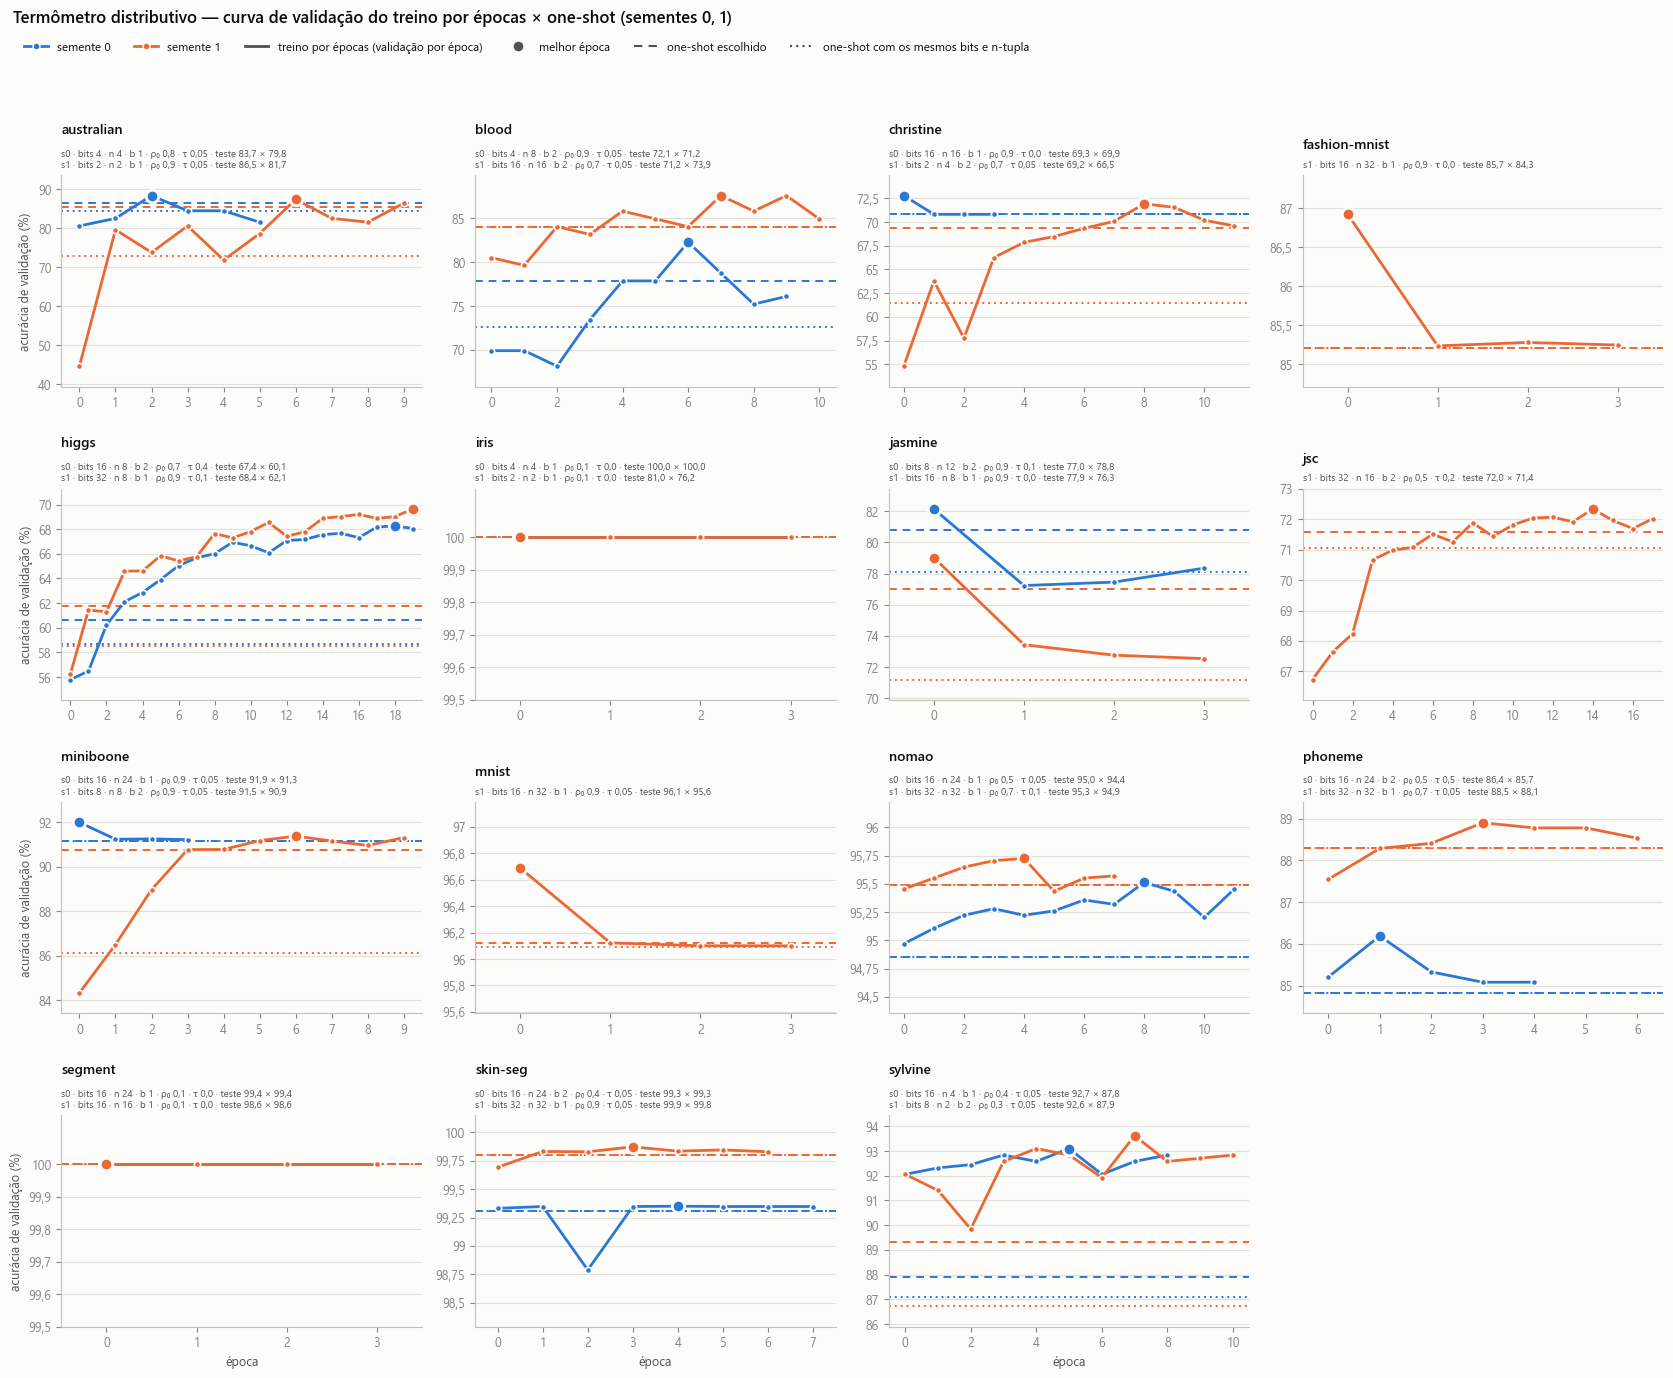

In [8]:
plot_encoding("distributive");

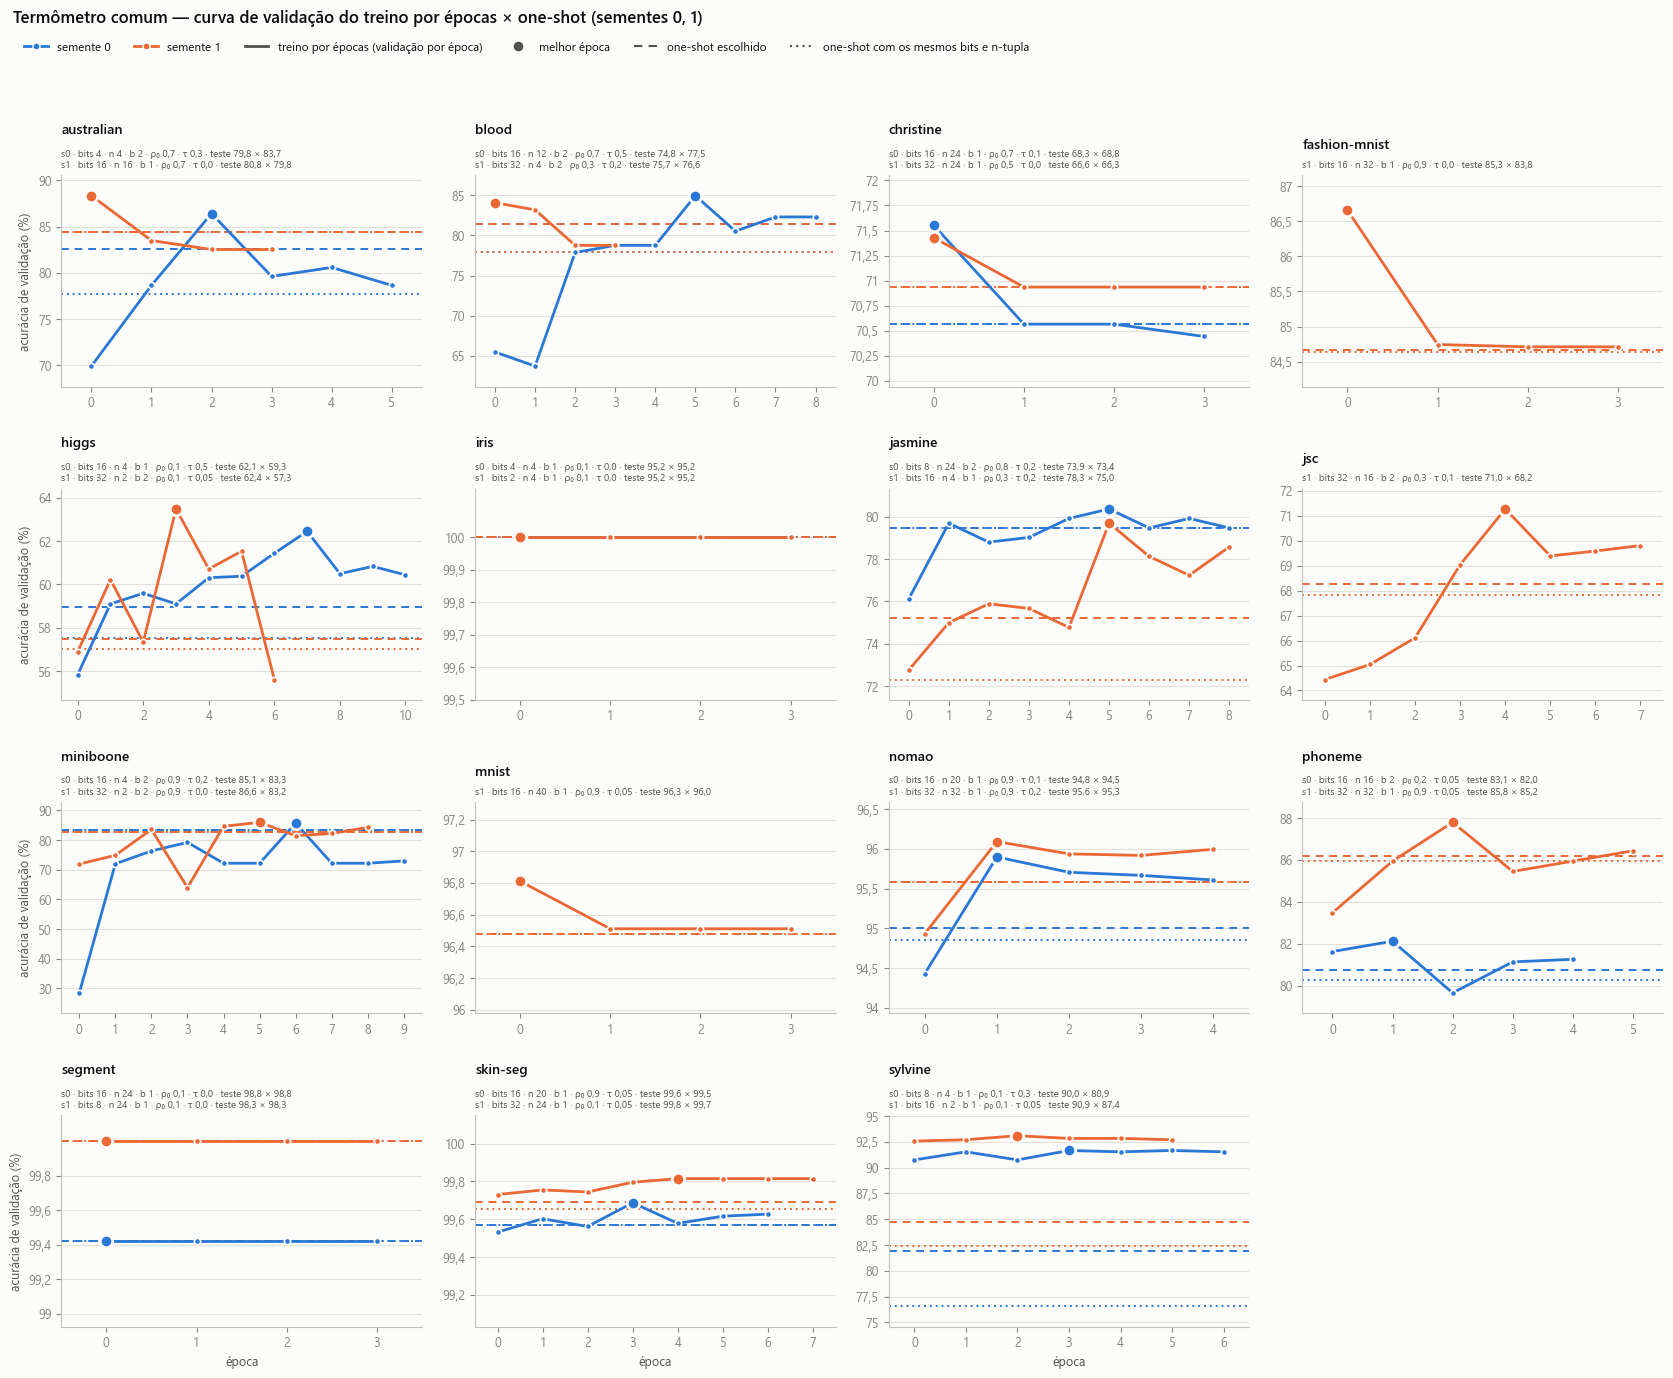

In [9]:
plot_encoding("thermometer");

## Um conjunto, as duas binarizações lado a lado

Troque o nome para ver outro conjunto (os nomes estão na tabela acima).

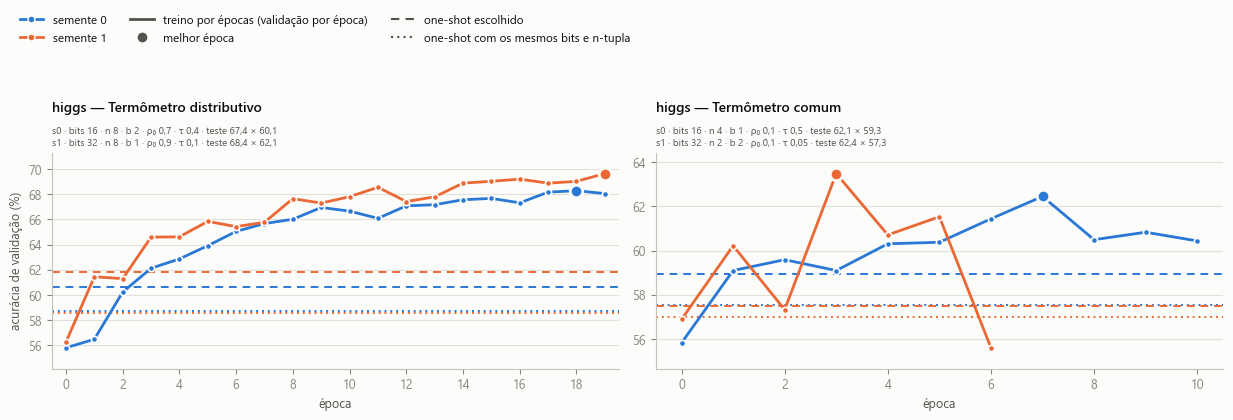

In [10]:
def plot_dataset(dataset):
    encodings = [e for e in ENCODINGS if any(r["dataset"] == dataset and r["encoding"] == e for r in records)]
    fig, axes = plt.subplots(1, len(encodings), figsize=(6.2 * len(encodings), 4.2), squeeze=False)
    for ax, encoding in zip(axes[0], encodings):
        plot_panel(ax, [r for r in records if r["dataset"] == dataset and r["encoding"] == encoding],
                   "%s — %s" % (dataset, ENCODINGS[encoding]))
        ax.set_xlabel("época")
    axes[0, 0].set_ylabel("acurácia de validação (%)")
    fig.legend(handles=legend_handles(ALL_SEEDS), loc="upper left", bbox_to_anchor=(0.01, 1.0), ncol=3, frameon=False, fontsize=8.5)
    fig.tight_layout(rect=(0, 0, 1, 0.8))
    return fig


plot_dataset("higgs");